# Decision Trees

## Classifying fruit with questions

A decision tree identifies a synthetic apple, orange, or banana from hue and length divided by width. The classes and measurement definitions match the fruit example, with a separately generated dataset. Each split asks a question such as “Is the length-to-width ratio at most this value?” and sends the fruit down one branch.

<img src="https://raw.githubusercontent.com/sonamu-jun/introduction-to-ai-convergence/main/07-1_Classification/assets/04_tree_splits.png" alt="A depth-two tree fitted to synthetic fruit uses its actual hue and shape thresholds to route measurements to apple, orange or banana leaves." width="512" style="max-width:100%;height:auto;">

A leaf estimates class probabilities from the training fruit that reach it:

$$
p_k=\frac{n_k}{n}, \qquad \hat y=\underset{k}{\arg\max}\;p_k.
$$

Here, $n_k$ counts class $k$ in the leaf and $n$ counts all fruit there. The most common class becomes the prediction. Leaf probabilities describe training proportions; a pure leaf does not guarantee a correct prediction for a new fruit.


## Choosing a split

Gini impurity measures how mixed the classes are in a node:

$$
G=1-\sum_{k=1}^{3}p_k^2.
$$

The proportion $p_k$ belongs to class $k$ in that node. A pure node has $G=0$; mixing labels raises $G$. The tree compares candidate splits using the weighted impurity of their children:

$$
G_{\text{split}}=\frac{n_L}{n}G_L+\frac{n_R}{n}G_R.
$$

Here, $L$ and $R$ denote the left and right children, with $n_L+n_R=n$. The weights account for how many records enter each branch. A split is preferred when it reduces impurity more. The tree repeats this local choice until a stopping rule is reached; it does not search every complete tree.

The depth control limits splits along each path. A shallow tree can merge distinct fruit classes and underfit. Extra depth can isolate rare observations and overfit; it does not necessarily improve validation accuracy. Colored points are validation fruit, while the background and star use the selected tree's predictions.

`Validation best` chooses among depth limits 1, 2, 3, 5, and 7, preferring the shallower tree on a tie. Controls do not change that candidate list. The displayed validation score is not a final test result.


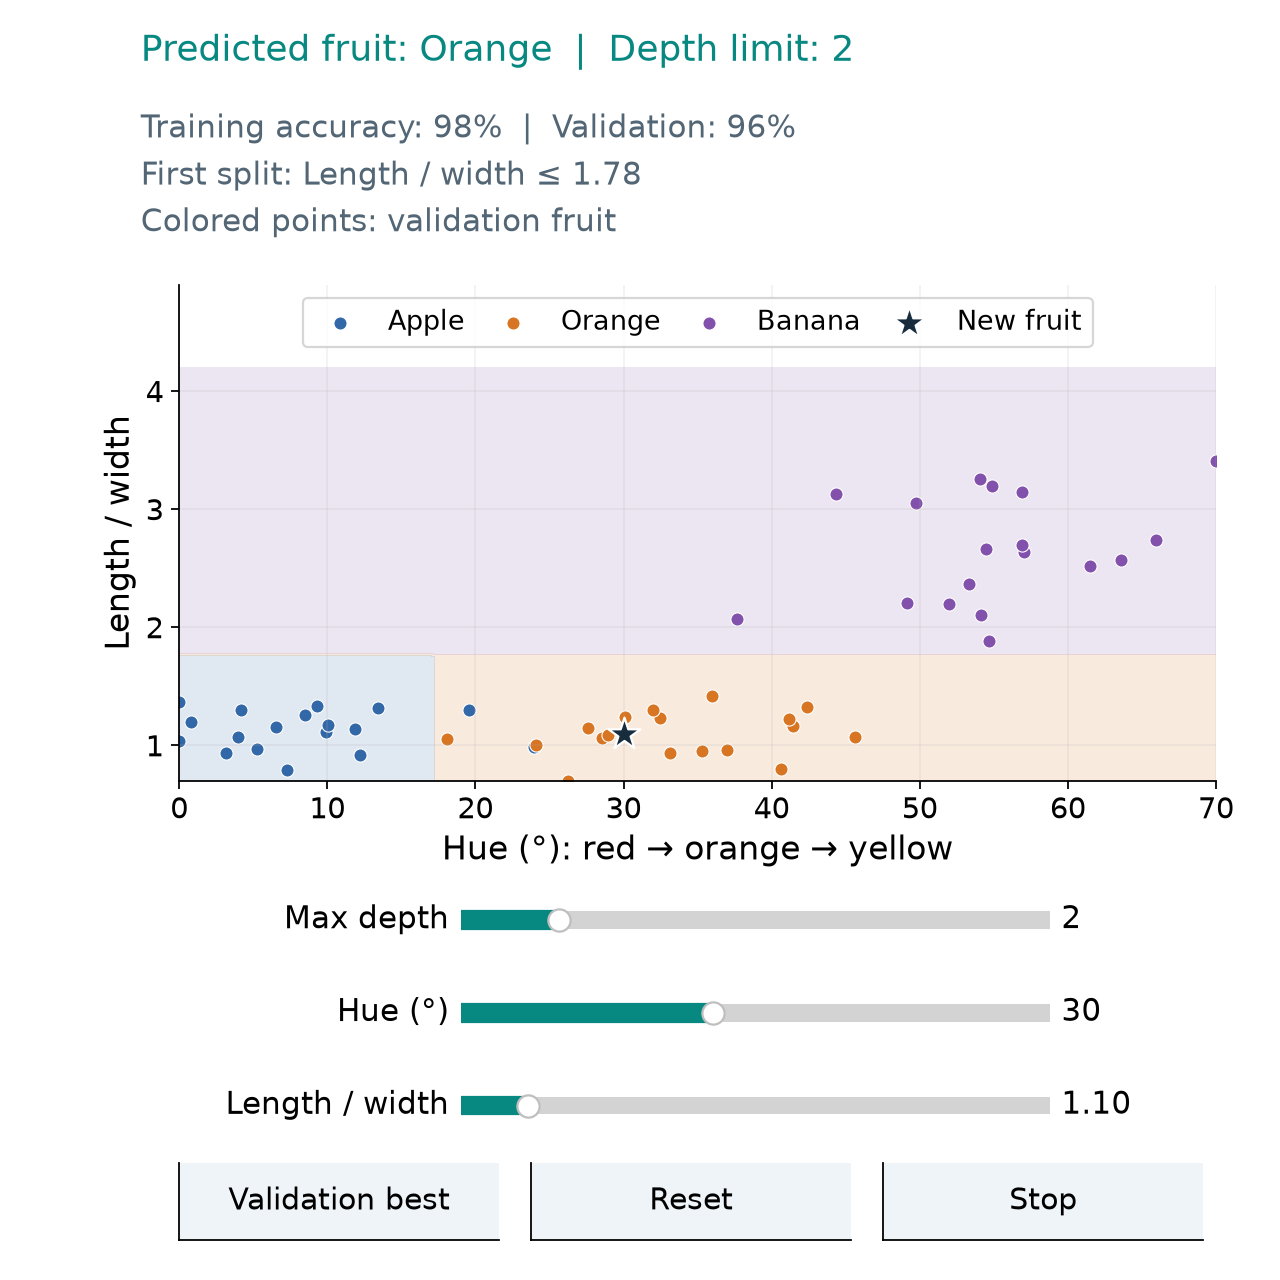

In [1]:
import os
import sys
import io
import numpy as np
import matplotlib

CLASSIFICATION_STATIC = os.environ.get("CLASSIFICATION_STATIC") == "1"
CLASSIFICATION_BROWSER = sys.platform == "emscripten"
if not CLASSIFICATION_STATIC and not CLASSIFICATION_BROWSER:
    from IPython import get_ipython
    shell = get_ipython()
    if shell is not None and getattr(shell, "kernel", None) is not None:
        shell.run_line_magic("matplotlib", "widget")

import matplotlib.pyplot as plt
from matplotlib.widgets import Slider, Button
from matplotlib.colors import ListedColormap
from IPython.display import Image, display
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

plt.rcParams.update({
    "font.size": 15, "axes.labelsize": 15,
    "xtick.labelsize": 13, "ytick.labelsize": 13, "legend.fontsize": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": .16, "lines.linewidth": 2.5,
    "axes.unicode_minus": False, "figure.facecolor": "white",
})
BLUE, TEAL, ORANGE, PURPLE = "#3268a8", "#078880", "#d87522", "#8251ac"


def sigmoid(score):
    score = np.clip(np.asarray(score, dtype=float), -500, 500)
    return 1 / (1 + np.exp(-score))


def softmax(scores):
    scores = np.asarray(scores, dtype=float)
    weights = np.exp(scores - scores.max(axis=-1, keepdims=True))
    return weights / weights.sum(axis=-1, keepdims=True)


def binary_loss(labels, scores):
    # The logaddexp form avoids taking log(0) at extreme scores.
    return float(np.mean(np.logaddexp(0, scores) - labels * scores))


def classification_metrics(observed, predicted):
    observed, predicted = np.asarray(observed), np.asarray(predicted)
    tp = int(np.sum((observed == 1) & (predicted == 1)))
    tn = int(np.sum((observed == 0) & (predicted == 0)))
    fp = int(np.sum((observed == 0) & (predicted == 1)))
    fn = int(np.sum((observed == 1) & (predicted == 0)))
    return {"TP": tp, "TN": tn, "FP": fp, "FN": fn,
            "accuracy": (tp + tn) / len(observed),
            "precision": tp / (tp + fp) if tp + fp else np.nan,
            "recall": tp / (tp + fn) if tp + fn else np.nan,
            "F1": 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else np.nan}


def percent(value):
    return "undefined" if not np.isfinite(value) else f"{value:.0%}"


# A rerun releases the previous figure and its input callbacks first.
for _previous_view in globals().get("_classification_views", {}).values():
    _previous_view.close()
_classification_views = {}


class ClassificationExplorer:
    """One figure keeps the selected model, predictions and scores together."""

    def __init__(self, name, render, sliders, actions=()):
        self.render = render
        self.slider_specs = sliders
        self.controls, self.buttons, self.state = {}, {}, {}
        self.stopped = False
        self.defaults = {key: initial for key, label, low, high, initial, step, fmt in sliders}
        with plt.ioff():
            height = min(8.0, 6.8 + .58 * len(sliders))
            self.figure = plt.figure(figsize=(8, height), dpi=64)
        self.status = self.figure.text(.11, 1 - .38 / height, "", fontsize=16, color=TEAL)
        self.detail = self.figure.text(.11, 1 - .66 / height, "", va="top", fontsize=14, color="#536675", linespacing=1.5)
        bottom = (1.38 + .58 * len(sliders)) / height
        top = 1 - 1.78 / height
        self.ax = self.figure.add_axes([.14, bottom, .81, top - bottom])
        for i, (key, label, low, high, initial, step, fmt) in enumerate(sliders):
            y = (.98 + .58 * (len(sliders) - i - 1)) / height
            slider = Slider(self.figure.add_axes([.36, y, .46, .22 / height]),
                            label, low, high, valinit=initial, valstep=step,
                            valfmt=fmt, color=TEAL)
            slider.label.set_fontsize(14)
            slider.valtext.set_fontsize(14)
            slider.on_changed(self.update)
            self.controls[key] = slider
        commands = list(actions) + [("Reset", lambda view: view.reset()),
                                    ("Stop", lambda view: view.stop())]
        self.commands = commands
        width = min(.25, .83 / len(commands) - .025)
        for i, (label, callback) in enumerate(commands):
            button = Button(self.figure.add_axes([.14 + i * (width + .025), .25 / height, width, .48 / height]),
                            label, color="#eef4f7", hovercolor="#d7e9e6")
            button.label.set_fontsize(13.5)
            button.on_clicked(lambda event, cb=callback: cb(self) if not self.stopped else None)
            self.buttons[label] = button
        self.figure.canvas.mpl_connect("close_event", lambda event: self.stop())
        _classification_views[name] = self
        self.update()

    def update(self, _=None):
        if self.stopped:
            return
        self.ax.clear()
        self.state = self.render(self, **{key: slider.val for key, slider in self.controls.items()})
        self.figure.canvas.draw_idle()
        self.refresh_local()

    def set_values(self, **values):
        if self.stopped:
            return
        for key, value in values.items():
            slider = self.controls[key]
            events, drawing = slider.eventson, slider.drawon
            slider.eventson = slider.drawon = False
            slider.set_val(value)
            slider.eventson, slider.drawon = events, drawing
        self.update()

    def reset(self):
        self.set_values(**self.defaults)

    def refresh_local(self):
        if not hasattr(self, "local_image"):
            return
        from matplotlib.transforms import Bbox
        width, height = self.figure.get_size_inches()
        # Crop only the embedded Matplotlib controls; native widgets follow the chart.
        lower = max(0, self.ax.get_position().y0 * height - .78)
        buffer = io.BytesIO()
        self.figure.savefig(buffer, format="png", dpi=64, facecolor="white",
                            bbox_inches=Bbox.from_extents(0, lower, width, height))
        self.local_image.value = buffer.getvalue()
        self.syncing_local = True
        for key, control in self.local_controls.items():
            control.value = self.controls[key].val
        self.syncing_local = False

    def start_local(self):
        from ipywidgets import Image as WidgetImage, FloatSlider, IntSlider
        from ipywidgets import Button as WidgetButton, HBox, VBox, Layout
        self.syncing_local = False
        self.local_image = WidgetImage(format="png", layout=Layout(
            width="100%", max_width="512px", height="auto"))
        self.local_controls, self.local_buttons = {}, {}
        for key, label, low, high, initial, step, fmt in self.slider_specs:
            slider_type = IntSlider if fmt == "%0.0f" and step == 1 else FloatSlider
            control = slider_type(value=initial, min=low, max=high, step=step,
                                  description=label, readout_format=fmt.replace("%0", ""),
                                  continuous_update=True,
                                  style={"description_width": "120px"},
                                  layout=Layout(width="100%", max_width="512px"))
            def changed(change, key=key):
                if not self.syncing_local and not self.stopped:
                    self.controls[key].set_val(change["new"])
            control.observe(changed, names="value")
            self.local_controls[key] = control
        for label, callback in self.commands:
            button = WidgetButton(description=label, layout=Layout(
                flex="1 1 0", min_width="120px", height="34px", margin="2px"))
            button.on_click(lambda _, cb=callback: cb(self) if not self.stopped else None)
            self.local_buttons[label] = button
        row = HBox(list(self.local_buttons.values()), layout=Layout(width="100%", flex_flow="row wrap"))
        self.local_row = row
        self.local_output = VBox([self.local_image, *self.local_controls.values(), row],
                                layout=Layout(width="100%", max_width="512px"))
        self.refresh_local()
        display(self.local_output)

    def start(self):
        if CLASSIFICATION_STATIC:
            buffer = io.BytesIO()
            self.figure.savefig(buffer, format="png", dpi=160, facecolor="white")
            display(Image(data=buffer.getvalue(), width=512,
                          alt=self.status.get_text() + ". " + self.detail.get_text()))
            plt.close(self.figure)
        elif CLASSIFICATION_BROWSER:
            # JSPCV sends mouse events after this cell has returned.
            plt.show(block=False)
        elif hasattr(self.figure.canvas, "toolbar_visible"):
            # The ipympl figure supplies a responsive chart with native widget controls.
            self.start_local()
        else:
            plt.show(block=False)

    def stop(self):
        if self.stopped:
            return
        self.stopped = True
        for control in list(self.controls.values()) + list(self.buttons.values()):
            control.set_active(False)
        for control in [*getattr(self, "local_controls", {}).values(),
                        *getattr(self, "local_buttons", {}).values()]:
            control.disabled = True
        if hasattr(self, "local_buttons"):
            self.local_buttons["Stop"].description = "Stopped"
        self.buttons["Stop"].label.set_text("Stopped")
        self.figure.canvas.draw_idle()

    def close(self):
        self.stop()
        for control in list(self.controls.values()) + list(self.buttons.values()):
            control.disconnect_events()
        plt.close(self.figure)
        if hasattr(self, "local_output"):
            self.local_output.close()
            self.local_image.close()
            self.local_row.close()
            for control in [*self.local_controls.values(), *self.local_buttons.values()]:
                control.close()



def make_messages(seed, count=240, spam_fraction=.35):
    """Synthetic labels and counts; no real messages or URLs are collected."""
    rng = np.random.default_rng(seed)
    labels = np.zeros(count, dtype=int)
    labels[:round(count * spam_fraction)] = 1
    rng.shuffle(labels)
    phrases = rng.binomial(10, np.where(labels == 1, .53, .13))
    links = rng.binomial(4, np.where(labels == 1, .57, .13))
    return np.column_stack([phrases, links]), labels


def make_fruit(seed):
    """Synthetic fruit measurements: hue in degrees and length / width."""
    rng = np.random.default_rng(seed)
    labels = np.repeat(np.arange(3), 60)
    centers = np.array([[8, 1.15], [30, 1.05], [53, 2.8]])
    spreads = np.array([[8, .18], [7, .16], [7, .5]])
    values = centers[labels] + rng.normal(size=(len(labels), 2)) * spreads[labels]
    return np.clip(values, [0, .7], [70, 4.2]), labels

fruit, labels = make_fruit(72)
class_names = np.array(["Apple", "Orange", "Banana"])
class_colors = [BLUE, ORANGE, PURPLE]
train_id, validation_id = train_test_split(np.arange(len(labels)), test_size=.3,
                                         stratify=labels, random_state=72)
tree_models = {depth: DecisionTreeClassifier(max_depth=depth, random_state=72).fit(
    fruit[train_id], labels[train_id]) for depth in range(1, 8)}
candidate_depths = (1, 2, 3, 5, 7)
validation_scores = {depth: model.score(fruit[validation_id], labels[validation_id])
                     for depth, model in tree_models.items()}
# Ties favor the shallower model; slider changes do not alter the candidate set.
best_depth = max(candidate_depths, key=lambda depth: (validation_scores[depth], -depth))
hue_grid, shape_grid = np.meshgrid(np.linspace(0, 70, 141), np.linspace(.7, 4.2, 101))
fruit_grid = np.c_[hue_grid.ravel(), shape_grid.ravel()]
region_cache = {depth: model.predict(fruit_grid).reshape(hue_grid.shape)
                for depth, model in tree_models.items()}


def render_tree(view, depth, hue, shape):
    model = tree_models[int(depth)]
    query = np.array([[hue, shape]])
    predicted = int(model.predict(query)[0])
    probability = model.predict_proba(query)[0]
    train_accuracy = model.score(fruit[train_id], labels[train_id])
    ax = view.ax
    ax.contourf(hue_grid, shape_grid, region_cache[int(depth)], levels=[-.5, .5, 1.5, 2.5],
                colors=class_colors, alpha=.15)
    for value, (color, name) in enumerate(zip(class_colors, class_names)):
        selected = validation_id[labels[validation_id] == value]
        ax.scatter(fruit[selected, 0], fruit[selected, 1], color=color, s=35,
                   edgecolor="white", linewidth=.5, label=name)
    ax.scatter([hue], [shape], s=230, marker="*", color="#172d3e",
               edgecolor="white", linewidth=1, label="New fruit", zorder=5)
    ax.set(xlim=(0, 70), ylim=(.7, 4.9), xlabel="Hue (°): red → orange → yellow",
           ylabel="Length / width")
    ax.legend(loc="upper center", ncol=4, fontsize=12, columnspacing=.8)
    root_feature = ["Hue", "Length / width"][model.tree_.feature[0]]
    view.status.set_text(f"Predicted fruit: {class_names[predicted]}  |  Depth limit: {int(depth)}")
    view.detail.set_text(f"Training accuracy: {train_accuracy:.0%}  |  Validation: {validation_scores[int(depth)]:.0%}\n"
                         f"First split: {root_feature} ≤ {model.tree_.threshold[0]:.2f}\n"
                         "Colored points: validation fruit")
    return {"prediction": predicted, "probability": probability, "model": model,
            "query": query, "train_accuracy": train_accuracy,
            "validation_accuracy": validation_scores[int(depth)]}


tree_demo = ClassificationExplorer("tree", render_tree, [
    ("depth", "Max depth", 1, 7, 2, 1, "%0.0f"),
    ("hue", "Hue (°)", 0, 70, 30, 1, "%0.0f"),
    ("shape", "Length / width", .7, 4.2, 1.1, .05, "%0.2f"),
], actions=[("Validation best", lambda view: view.set_values(depth=best_depth))])
tree_demo.start()


## A rule depends on its measurements

Each split uses one feature, so the decision regions are rectangular. A small data change can shift a threshold or select another branch. Depth and minimum leaf size limit complexity but cannot recover missing information.

Lighting can change measured hue, and an unusual fruit can resemble another class. These synthetic measurements do not represent every variety. After choosing depth using validation fruit, an untouched test set is needed to evaluate the final tree.
